# Activity8.01: World cities, European Voronoi and Delaunay

LU MENGJIE - MC643920

CARTO now requires an API key. With user approval, Esri public light/dark gray tiles replace CARTO, while the custom HOT provider is retained. The bundled official Geoplotlib source has Python 3 / NumPy / SciPy compatibility fixes; it is not a replacement plotting library.

## Activity8.01 - 01. Read and inspect cities

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../../Support').resolve()))
import course_maps
import geoplotlib
import pandas as pd
import numpy as np
from geoplotlib.utils import DataAccessObject, BoundingBox, read_csv
from IPython.display import display
DATA = Path('../../Datasets')
print('LU MENGJIE | MC643920 | Suggested Exercise 08')
print('Public Esri gray basemaps replace key-protected CARTO; HOT is the custom provider.')
dataset = pd.read_csv(DATA/'world_cities_pop.csv', low_memory=False)
display(dataset.head())
print(dataset.dtypes)
dataset = dataset.rename(columns={'Latitude':'lat','Longitude':'lon'})
print('All records:',len(dataset))

LU MENGJIE | MC643920 | Suggested Exercise 08
Public Esri gray basemaps replace key-protected CARTO; HOT is the custom provider.


,Country,City,AccentCity,Region,Population,Latitude,Longitude
0,ad,aixas,Aixàs,06,NaN,42.483333,1.466667
1,ad,aixirivali,Aixirivali,06,NaN,42.466667,1.500000
2,ad,aixirivall,Aixirivall,06,NaN,42.466667,1.500000
3,ad,aixirvall,Aixirvall,06,NaN,42.466667,1.500000
4,ad,aixovall,Aixovall,06,NaN,42.466667,1.483333


Country           str
City              str
AccentCity        str
Region            str
Population    float64
Latitude      float64
Longitude     float64
dtype: object
All records: 3173958


## Activity8.01 - 02. All cities dot map

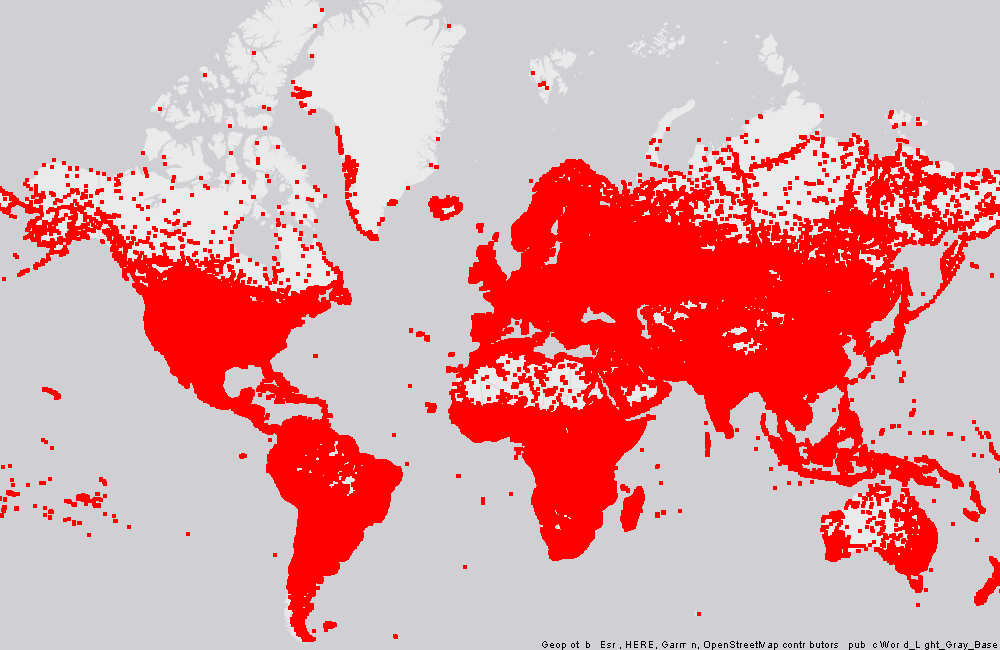

In [2]:
geoplotlib.dot(DataAccessObject(dataset))
course_maps.snapshot('all_cities')

## Activity8.01 - 03. Country aggregation and population filter

,number_of_cities
Country,
ad,92
ae,446
af,88749
ag,183
ai,42
al,15123
am,2890
an,269
ao,19560


Average number of city records per country: 13563.923076923076
Records with population > 0: 47980


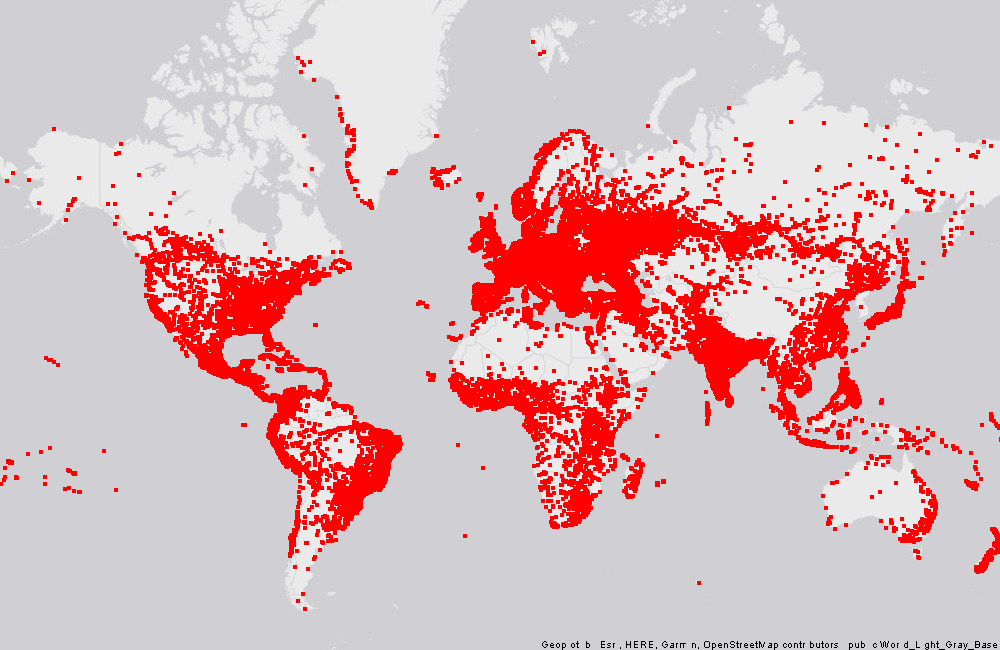

In [3]:
country_counts = dataset.groupby('Country').agg(number_of_cities=('City','size'))
display(country_counts.head(20))
print('Average number of city records per country:',country_counts['number_of_cities'].mean())
positive = dataset[dataset.Population > 0].copy()
print('Records with population > 0:',len(positive))
geoplotlib.dot(DataAccessObject(positive))
course_maps.snapshot('positive_population')

## Activity8.01 - 04. European large cities Voronoi

European cities with population > 100000: 507


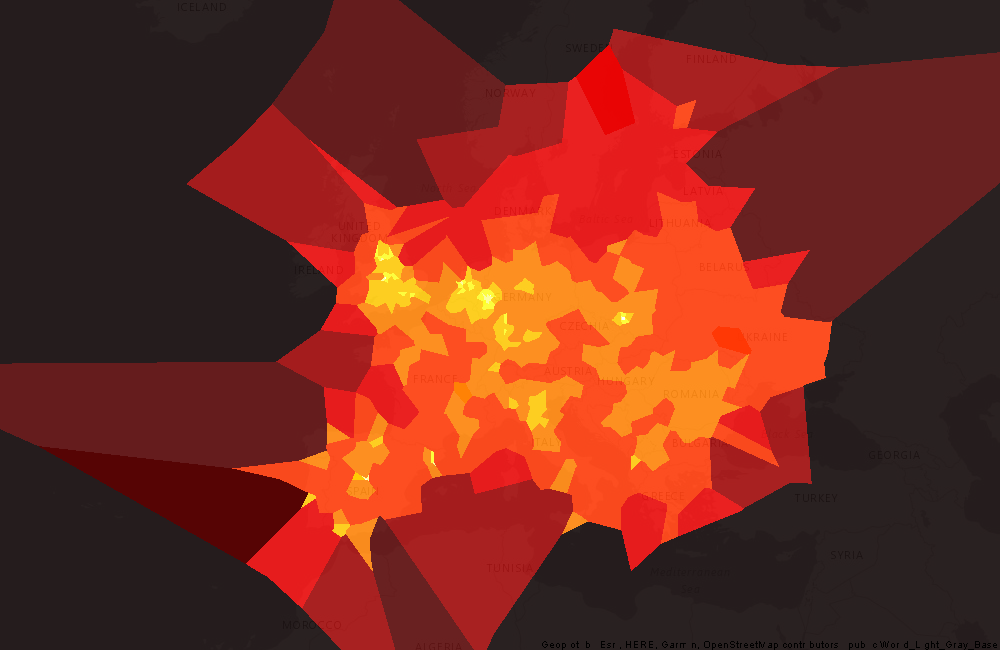

In [4]:
europe_country_codes = ['al','ad','at','by','be','ba','bg','hr','cy','cz','dk','ee','fo','fi','fr','de','gi','gr','hu','is','ie','im','it','xk','lv','li','lt','lu','mk','mt','md','mc','me','nl','no','pl','pt','ro','sm','rs','sk','si','es','se','ch','ua','gb','va']
large = positive[(positive.Population > 100000) & positive.Country.isin(europe_country_codes)].copy()
print('European cities with population > 100000:',len(large))
geoplotlib.voronoi(DataAccessObject(large), cmap='hot_r', max_area=1e5)
course_maps.snapshot('europe_voronoi')

## Activity8.01 - 05. Germany and Great Britain Delaunay

Selected cities: 150


Country
de    81
gb    69
Name: cities, dtype: int64

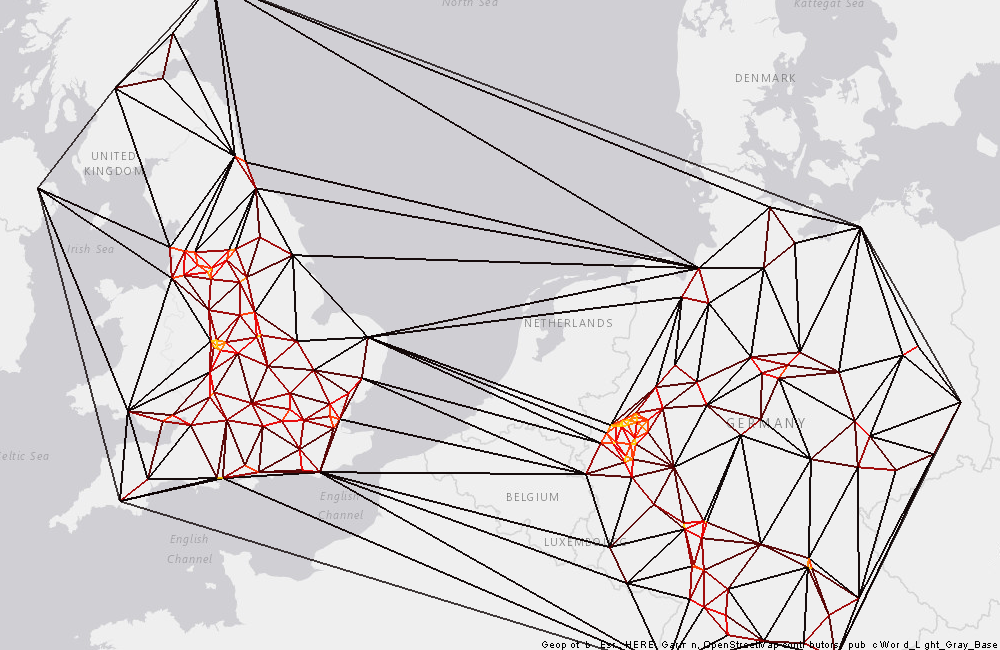

In [5]:
selected = large[large.Country.isin(['de','gb'])].copy()
print('Selected cities:',len(selected))
display(selected.groupby('Country').size().rename('cities'))
geoplotlib.delaunay(DataAccessObject(selected), cmap='hot_r')
course_maps.snapshot('germany_britain_delaunay')